# ACCESS-OM3 and ACCESS-OM2 timeseries
Includes both scalar variables and spatial averages of 2d variables.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/"
nbname = "timeseries.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file, get_exptname_from_path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
%matplotlib inline
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()  # conda env workaround; no-op on healthy envs

import pandas as pd
import intake
import xarray as xr
import numpy as np
import cf_xarray as cfxr
import pint_xarray
from pint import application_registry as ureg
import cf_xarray.units
import cftime
import xgcm
import os

import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft

from dask.distributed import Client

In [5]:
xr.set_options(keep_attrs=True); # cf_xarray works best when xarray keeps attributes by default

In [6]:
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35853,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43499,Total threads: 1
Dashboard: http://127.0.0.1:37083/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:40653,


In [7]:
thisdir = './'

In [8]:
IAF = esm_file.find('iaf') > 0
IAF

False

### Define data sources

In [9]:
catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                esm_file,  # the CM3/OM3 experiment under test -- already includes CM3 when esm_file is a CM3 path
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json",   # 100km RYF spin-up
            ]
if not IAF and model_name != "ACCESS-CM3":
    # RYF: the IAF comparison runs above don't share model years with an RYF run
    catalogs = [c for c in catalogs if "iaf" not in c or c == esm_file]
catalogs

['/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json',
 '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json']

In [10]:
datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c, columns_with_iterables=['variable'])
              for c in catalogs }
datastores

{'MC_8km_jra_ryf-test2-expt-c349f800': <datastore catalog with 32 dataset(s) from 3843 asset(s)>,
 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c': <experiment_datastore catalog with 15 dataset(s) from 8540 asset(s)>}

In [11]:
if model_name == "ACCESS-CM3":
    # ACCESS-CM2 cj877 control run reference (as in other CM3 notebooks).
    # Its scalar diagnostics use the same variable names as the OM2 catalog.
    om2expt = 'cj877'
    import glob
    _cm2_files = sorted(glob.glob('/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-scalar-1-daily-ym_*.nc'))
    om2cat = xr.open_mfdataset(_cm2_files, combine="by_coords", parallel=True, chunks={"time": 181},
                               decode_timedelta=False, use_cftime=True,
                               data_vars="minimal", coords="minimal", compat="override")
else:
    # ACCESS-OM2-025 experiment
    # use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258
    if IAF:
        om2expt = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2expt = '025deg_jra55_ryf9091_gadi'
    om2cat = intake.cat.access_nri[om2expt]

### Load grid data
This is needed for xgcm so we can get spatial averages of non-scalar data.

In [12]:
exptname = get_exptname_from_path(esm_file)
# filename regex matches om3 and cm3 static files
static = xr.open_dataset(datastores[exptname].search(filename=".*mom6.static.nc").df.loc[0, "path"]).drop_vars("time")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x155080ca3aa0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1550806694f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x155080d02f30>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x155080c5baa0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x155080d03680>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x155080d02090>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x15507b4eeab0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [13]:
# See https://xgcm.readthedocs.io/en/latest/xgcm-examples/03_MOM6/#xgcm-grid-definition
symmetric = True  # True for ACCESS-OM3 2025.08.000 and later

if symmetric:  # ACCESS-OM3 version 2025.08.000 and later: one more q point than h points
    coords={
        'X': {'center': 'xh', 'outer': 'xq'},
        'Y': {'center': 'yh', 'outer': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }
else:  # ACCESS-OM3 versions prior to 2025.08.000: equal number of q and h points
    coords={
        'X': {'center': 'xh', 'right': 'xq'},
        'Y': {'center': 'yh', 'right': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }

grid = xgcm.Grid(
    static,
    coords=coords,
    metrics = {
        ('X',): ['dxt', 'dxCu', 'dxCv'], # X distances
        ('Y',): ['dyt', 'dyCu', 'dyCv'], # Y distances
        ('X', 'Y'): ['areacello', 'areacello_cu', 'areacello_cv', 'areacello_bu'] # Areas
    },
    periodic=['X'],
    autoparse_metadata=False
# Note, autoparse_metadata=False is required below for xgcm >= 0.9.0 to prevent xgcm 
# from trying to autoparse non-existent grid information from the file metadata, 
# leading to the error:
# ValueError: Found two coordinates without `c_grid_axis_shift` attribute for axis X
)

### Define list of variables and load them

In [14]:
fields = { # key is OM3 name, value is OM2 name
    # 'mlotst': 'mld',
    # keys from ncdump -h ctrl_run_25km_0.5/archive/output009/access-om3.mom6.scalar.1day.snap.1962.nc | grep double
    'masso': None, # Mass of liquid ocean
    'soga': 'salt_global_ave',
    'thetaoga': 'temp_global_ave', # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'tosga': 'temp_surface_ave',   # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'sosga': 'salt_surface_ave',
    'speed_max': None,
    'mlotst_max': None,
    'tos_max': None,
    'tos_min': None,
    'sos_max': None,
    'sos_min': None,
    'zos_max': None,
    'zos_min': None, 
    'total_salt_Flux_Added': None,
    'total_salt_Flux_In': None,
    'total_salt_flux': None,
    'net_fresh_water_global_adjustment': None,
    'salt_flux_global_restoring_adjustment': None,
    'total_wfo': None,
    'total_evs': None,
    'total_fsitherm': None,
    'total_precip': None,
    'total_prsn': None,
    'total_lprec': None,
    'total_ficeberg': None,
    'total_friver': None,
    'total_net_massout': None,
    'total_net_massin': None,
}
fields

{'masso': None,
 'soga': 'salt_global_ave',
 'thetaoga': 'temp_global_ave',
 'tosga': 'temp_surface_ave',
 'sosga': 'salt_surface_ave',
 'speed_max': None,
 'mlotst_max': None,
 'tos_max': None,
 'tos_min': None,
 'sos_max': None,
 'sos_min': None,
 'zos_max': None,
 'zos_min': None,
 'total_salt_Flux_Added': None,
 'total_salt_Flux_In': None,
 'total_salt_flux': None,
 'net_fresh_water_global_adjustment': None,
 'salt_flux_global_restoring_adjustment': None,
 'total_wfo': None,
 'total_evs': None,
 'total_fsitherm': None,
 'total_precip': None,
 'total_prsn': None,
 'total_lprec': None,
 'total_ficeberg': None,
 'total_friver': None,
 'total_net_massout': None,
 'total_net_massin': None}

In [15]:
# from https://github.com/COSIMA/cosima-recipes/blob/main/Cooking-Lessons-101-Tutorials/ACCESS-NRI_Intake_Catalog.ipynb
# Speeding up opening your datasets
# Try passing the following argument to your to_dask or to_dataset_dict call:
# See the xarray documentation on Reading multi-file datasets for more details about these arguments.
# https://docs.xarray.dev/en/stable/user-guide/io.html#reading-multi-file-datasets

xarray_combine_by_coords_kwargs=dict(
    compat="override",
    data_vars="minimal",
    coords="minimal"
)

In [16]:
# load data, with lots of workarounds for disambiguation
data = dict()
for k, om2 in fields.items():
    print(k)
    # d = [ ds.search(variable=k).to_dataset_dict(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for ds in datastores ]
    try:
        d = { n: ds.search(variable=k) for n, ds in datastores.items() }
        d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
    except ValueError:
        try:
            d = { n: ds.search(variable=k, frequency='1mon', variable_cell_methods='.*time: mean.*') for n, ds in datastores.items() }
            d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
        except:
            try:
                d = { n: ds.search(variable=k, variable_cell_methods='.*time: mean.*') for n, ds in datastores.items() }
                d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
            except:
                try:
                    d = { n: ds.search(variable=k, variable_cell_methods='.*time: point.*') for n, ds in datastores.items() }
                    d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                except:
                    try:
                        d = { n: ds.search(variable=k, variable_cell_methods='.*time: min.*') for n, ds in datastores.items() }
                        d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                    except:
                        try:
                            d = { n: ds.search(variable=k, variable_cell_methods='.*time: max.*') for n, ds in datastores.items() }
                            d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                        except:
                            print(f'{k} failed')
                            continue
    if om2 is None: # add reference model data, with variable name changed to match om3
        d2 = {}
    elif model_name == "ACCESS-CM3":
        cm2_da = om2cat[[om2]].isel(scalar_axis=0, drop=True).rename({om2: k})  # drop dummy scalar_axis dim
        # relabel cj877 (cftime, model years) onto CM3's own datetime64 time axis,
        # matching elapsed time since each run's start (both are daily)
        _cm3t = d[exptname].time
        n = min(cm2_da.sizes["time"], _cm3t.sizes["time"])
        cm2_da = cm2_da.isel(time=slice(None, n)).assign_coords(time=("time", _cm3t.isel(time=slice(None, n)).values))
        d2 = {om2expt: cm2_da}
    else:
        # d[om2expt] = om2cat.search(variable=om2).to_dask().rename({om2: k})
        om2search = om2cat.search(variable=om2, frequency=d[list(d.keys())[0]].attrs['intake_esm_attrs:frequency'])
        if len(om2search) == 0:  # e.g. 025deg_jra55_ryf9091_gadi has monthly but not daily scalars
            om2search = om2cat.search(variable=om2, frequency='1mon')
        d2 = {om2expt: om2search.to_dask(  # cftime: the OM2 RYF control runs past the datetime64 range
                xarray_open_kwargs=dict(use_cftime=True)).rename({om2: k})}
    # if d:
    #     data[k] = xr.concat(d, 'time')
    # else:
    #     print(f'no data for {k}')
    # break
    data[k] = d2 | d
    # break

if IAF:
    for vname, d in data.items():
        for expt in d.keys():
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# RYF spin-up runs use a synthetic calendar (e.g. starting ~1900s) unrelated to real
# forcing dates, so their time axis does not overlap the IAF experiments at all.
# Relabel onto the primary experiment's real time axis so the RYF run plots on the
# same timescale as the IAF runs. Only applied to the RYF experiment.
_ryf_expt = "MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c"
for _vname, _d in data.items():
    if _ryf_expt not in _d or exptname not in _d:
        continue
    _ref = _d[exptname].time
    _rds = _d[_ryf_expt]
    _n = min(_rds.sizes["time"], _ref.sizes["time"])
    _d[_ryf_expt] = (_rds.isel(time=slice(None, _n))
                         .assign_coords(time=("time", _ref.isel(time=slice(None, _n)).values)))

data

masso


soga


thetaoga


tosga


sosga


...

total_ficeberg


total_friver


total_net_massout


total_net_massin


{'masso': {'MC_8km_jra_ryf-test2-expt-c349f800': <xarray.Dataset> Size: 58kB
  Dimensions:      (time: 3650, scalar_axis: 1)
  Coordinates:
    * time         (time) object 29kB 1900-01-02 00:00:00 ... 1910-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 29kB dask.array<chunksize=(59, 1), meta=np.ndarray>
  Attributes: (12/15)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_attrs:variable_units:          ['Celsius', 'kg', 'kg m-2 s-1',...
      intake_esm_attrs

In [17]:
data.keys()

dict_keys(['masso', 'soga', 'thetaoga', 'tosga', 'sosga', 'speed_max', 'mlotst_max', 'tos_max', 'tos_min', 'sos_max', 'sos_min', 'zos_max', 'zos_min', 'total_salt_Flux_Added', 'total_salt_Flux_In', 'total_salt_flux', 'net_fresh_water_global_adjustment', 'salt_flux_global_restoring_adjustment', 'total_wfo', 'total_evs', 'total_fsitherm', 'total_precip', 'total_prsn', 'total_lprec', 'total_ficeberg', 'total_friver', 'total_net_massout', 'total_net_massin'])

In [18]:
data

{'masso': {'MC_8km_jra_ryf-test2-expt-c349f800': <xarray.Dataset> Size: 58kB
  Dimensions:      (time: 3650, scalar_axis: 1)
  Coordinates:
    * time         (time) object 29kB 1900-01-02 00:00:00 ... 1910-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 29kB dask.array<chunksize=(59, 1), meta=np.ndarray>
  Attributes: (12/15)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_attrs:variable_units:          ['Celsius', 'kg', 'kg m-2 s-1',...
      intake_esm_attrs

### Plot timeseries

In [19]:
# set date range
# trange = slice(cftime.DatetimeNoLeap(1900, 1, 1, 0, 0, 0, 0),
#                cftime.DatetimeNoLeap(1960, 1, 1, 0, 0, 0, 0))
trange = slice(None, None)  # all available
if not IAF and model_name != "ACCESS-CM3":
    # RYF: the OM2 RYF control is centuries long, so only plot the model years of this run
    _years = next(d[exptname].time.dt.year for d in data.values() if exptname in d)
    trange = slice(f"{int(_years[0]):04d}-01-01", f"{int(_years[-1]):04d}-12-31")
trange

slice('1900-01-01', '1910-12-31', None)

masso


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
soga


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
thetaoga


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
tosga


...

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_24.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
total_ficeberg


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_25.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
total_friver


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_26.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
total_net_massout


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_27.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.
total_net_massin


Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries_28.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-3/mkmd/timeseries.md successfully.


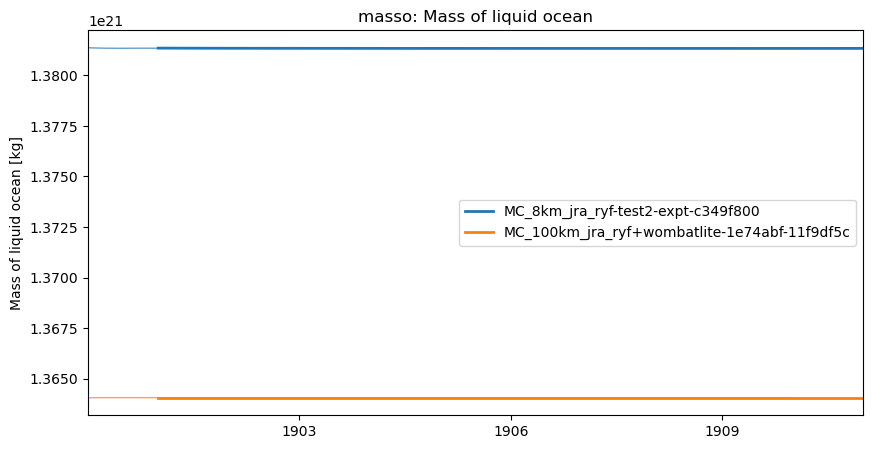

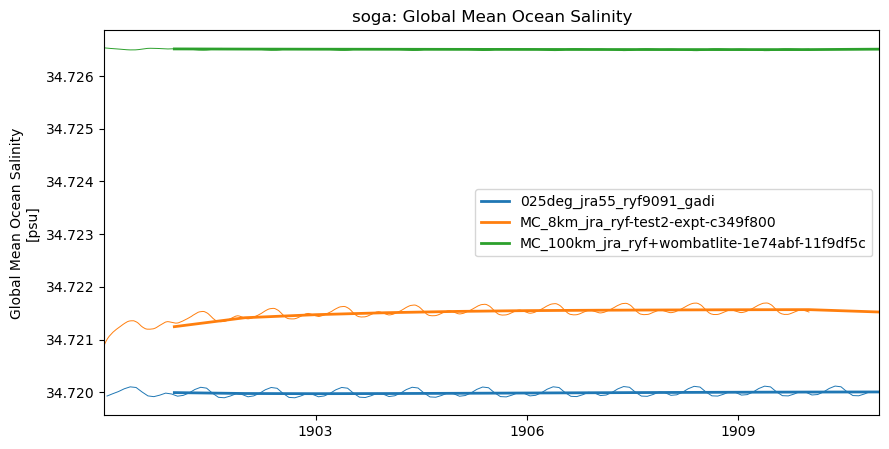

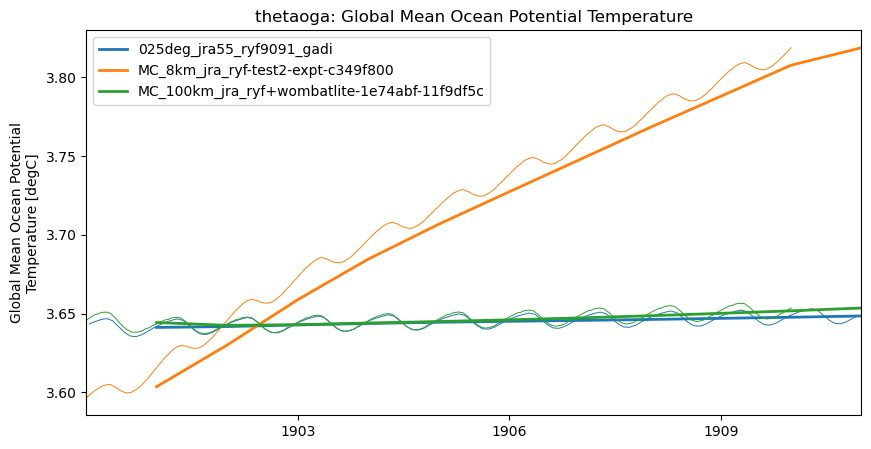

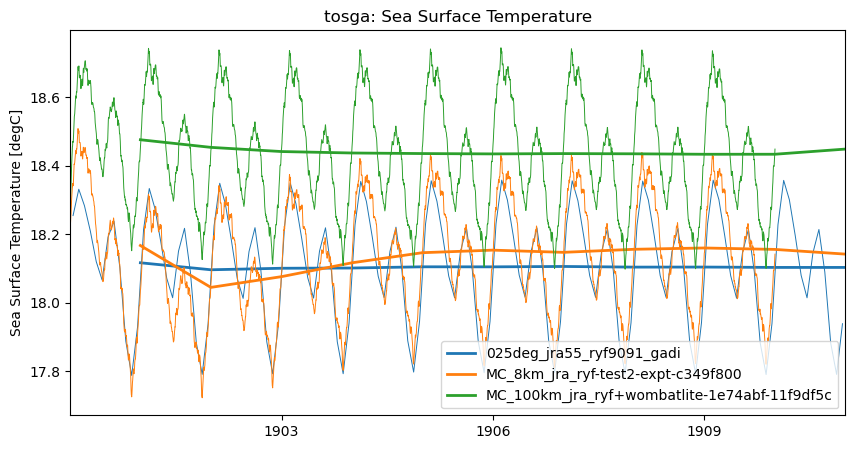

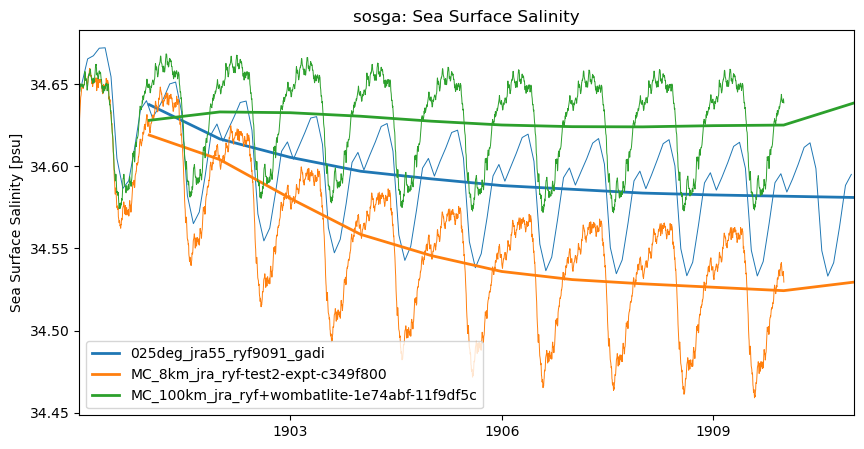

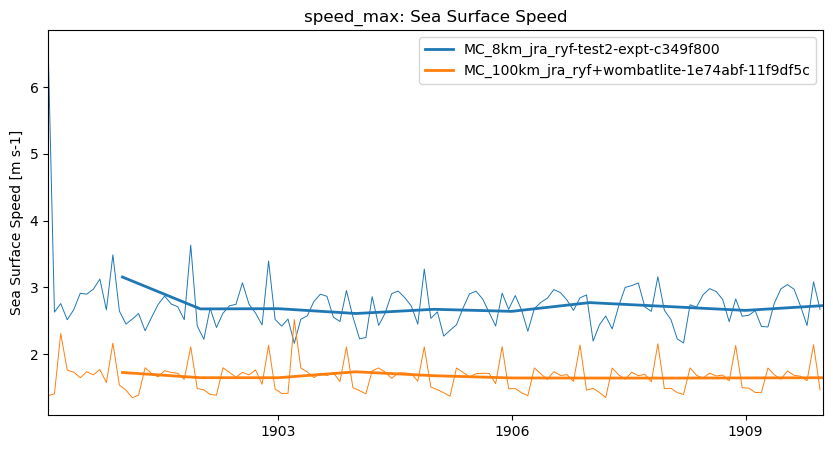

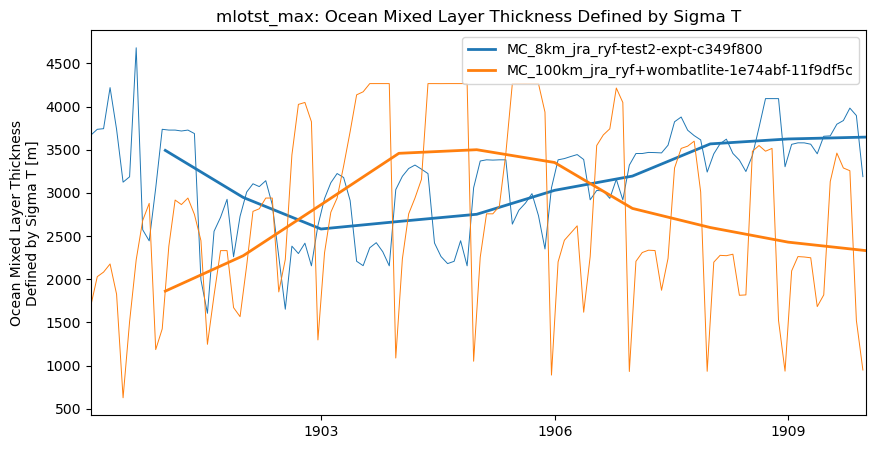

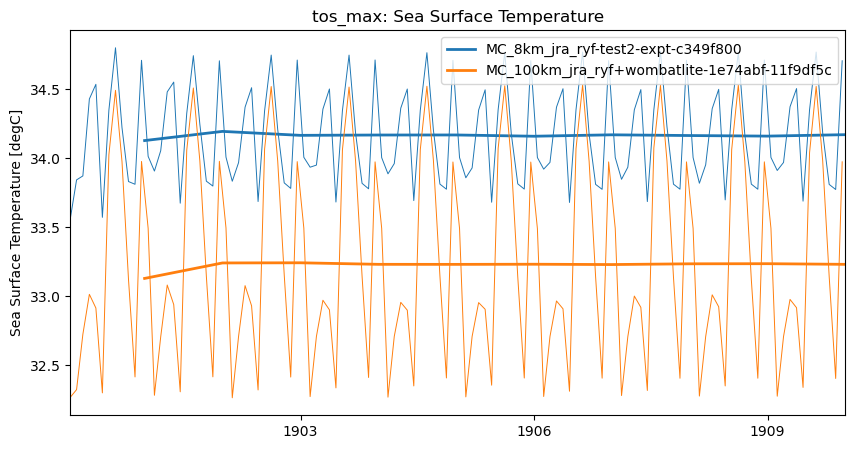

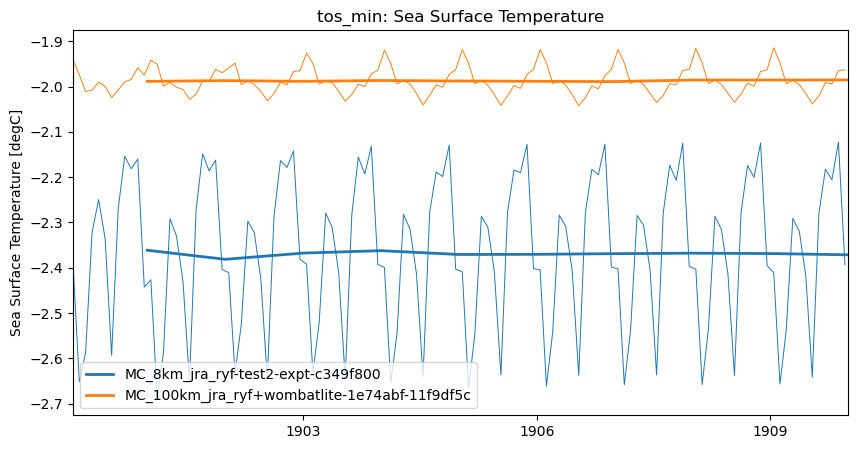

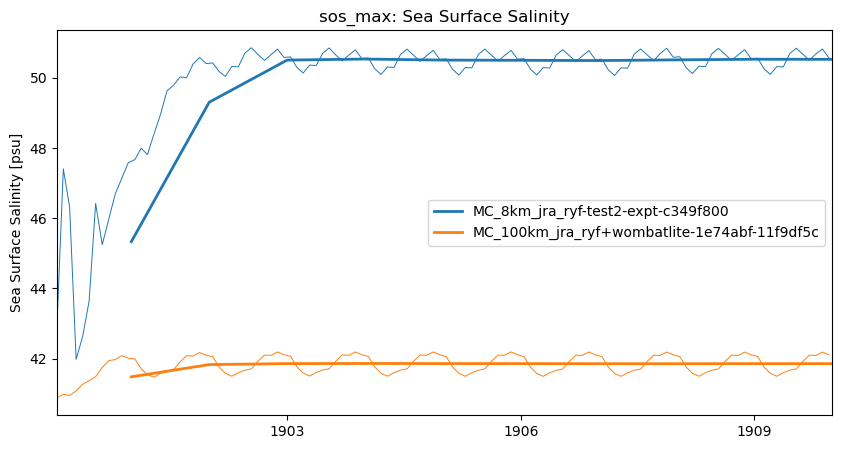

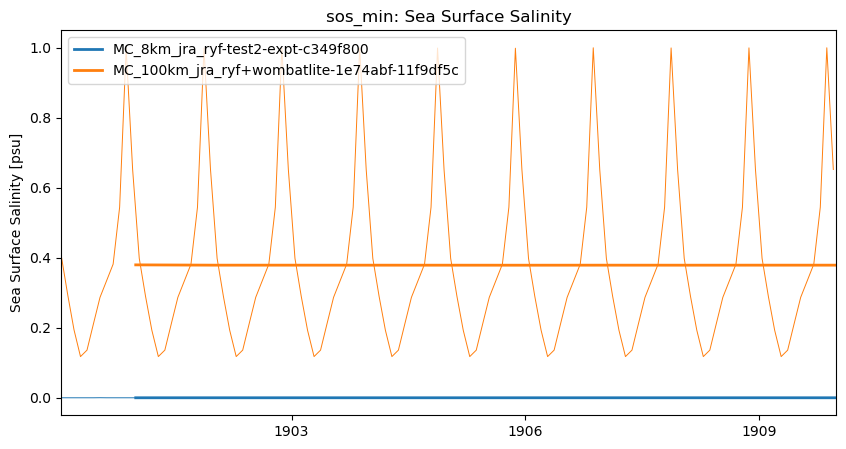

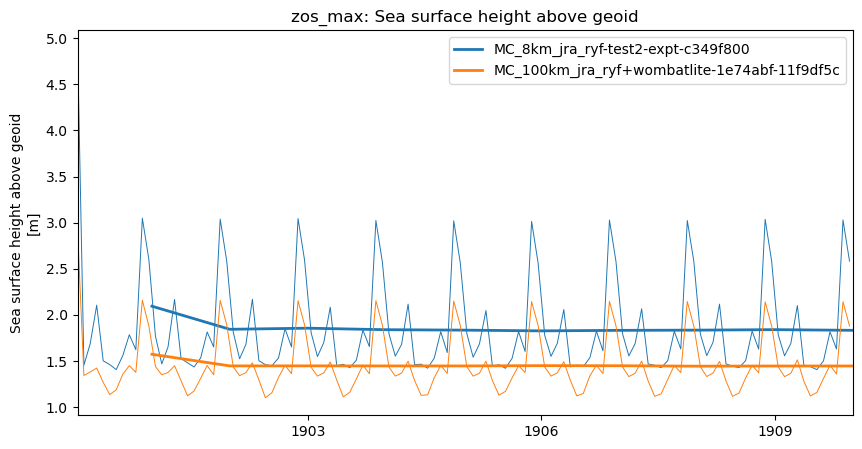

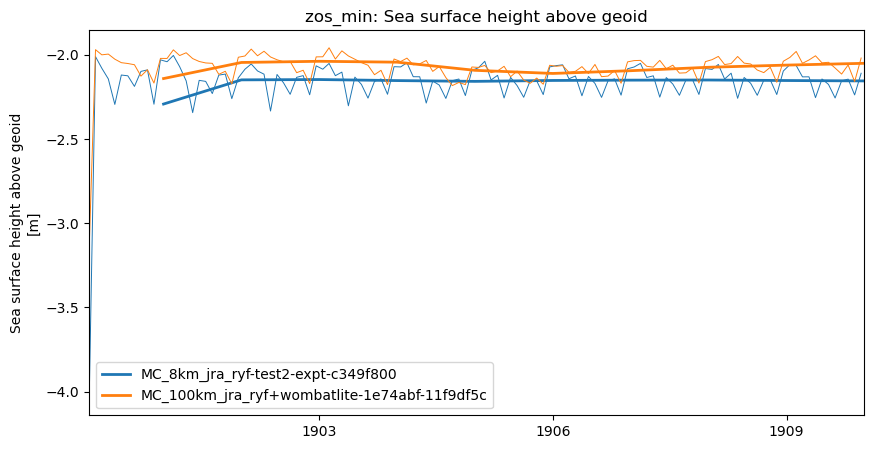

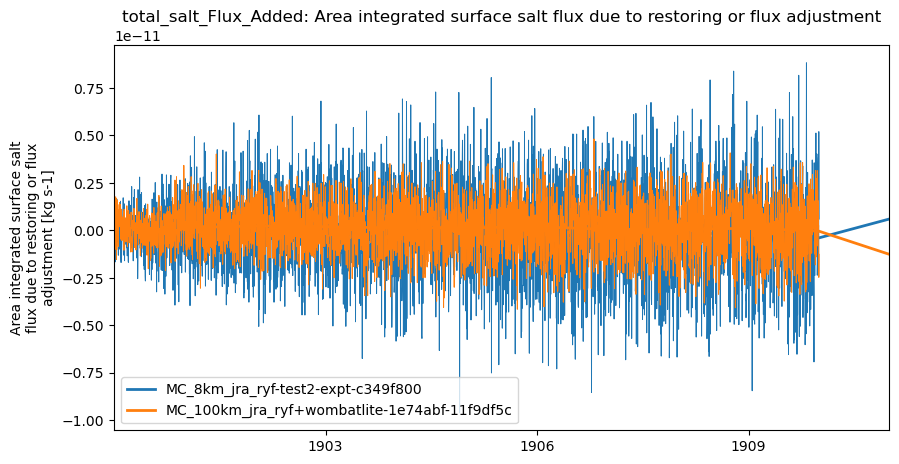

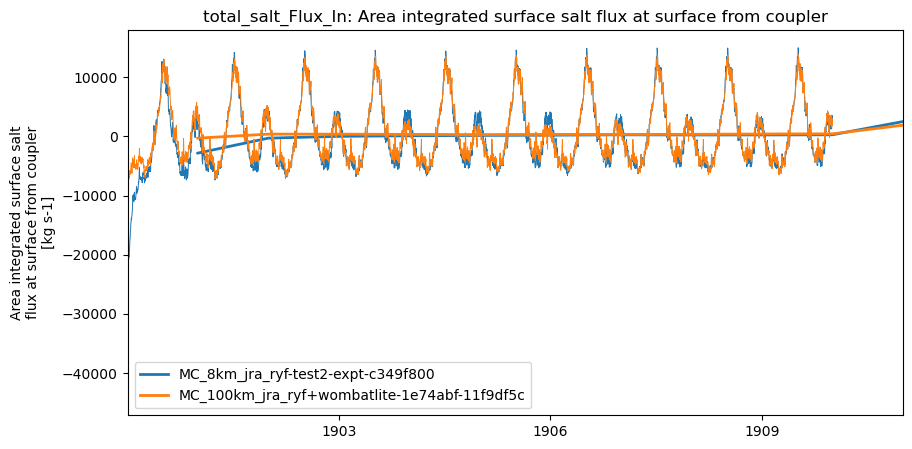

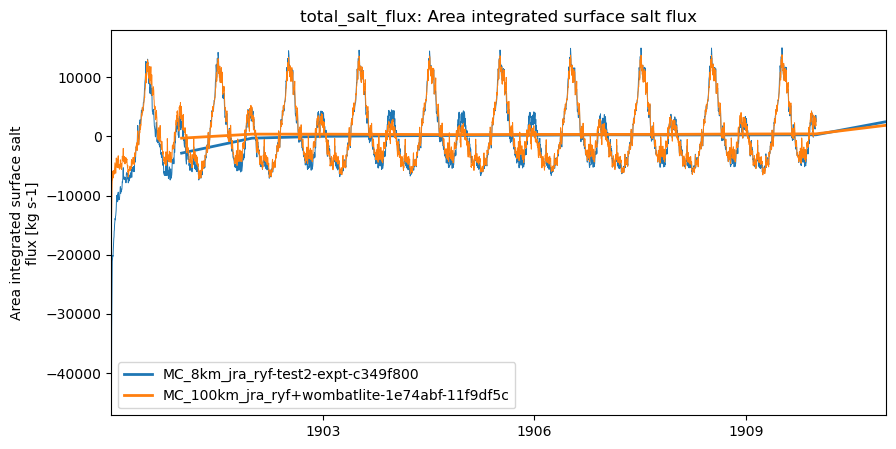

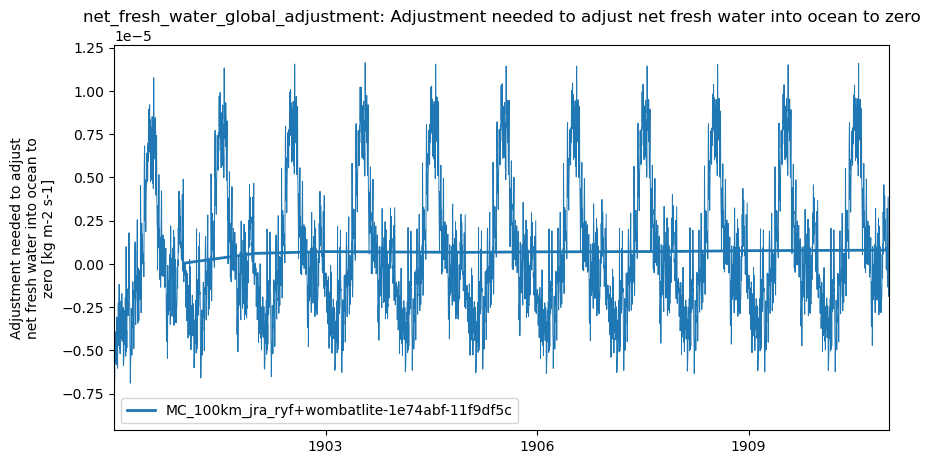

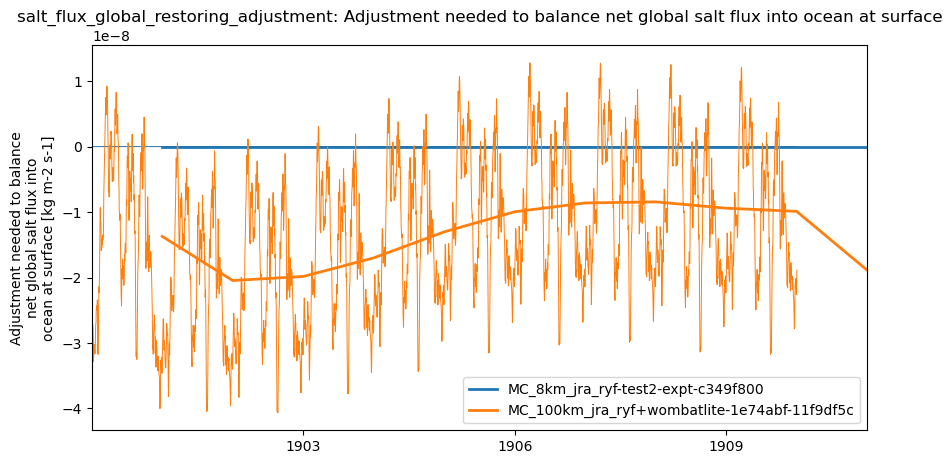

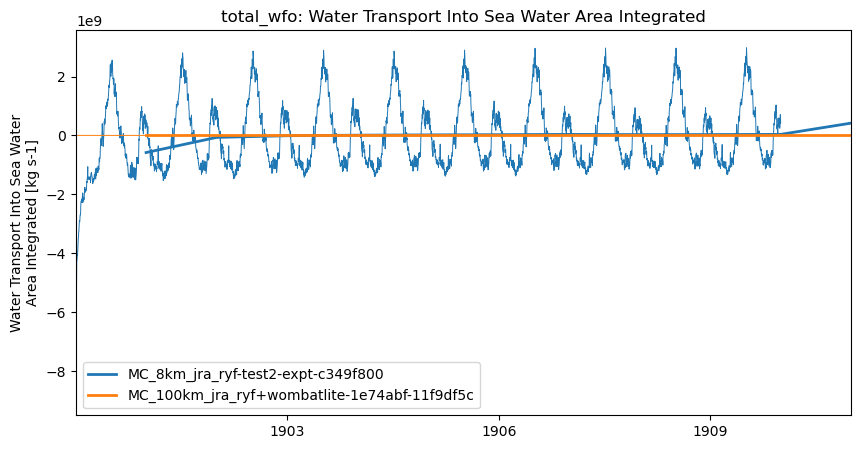

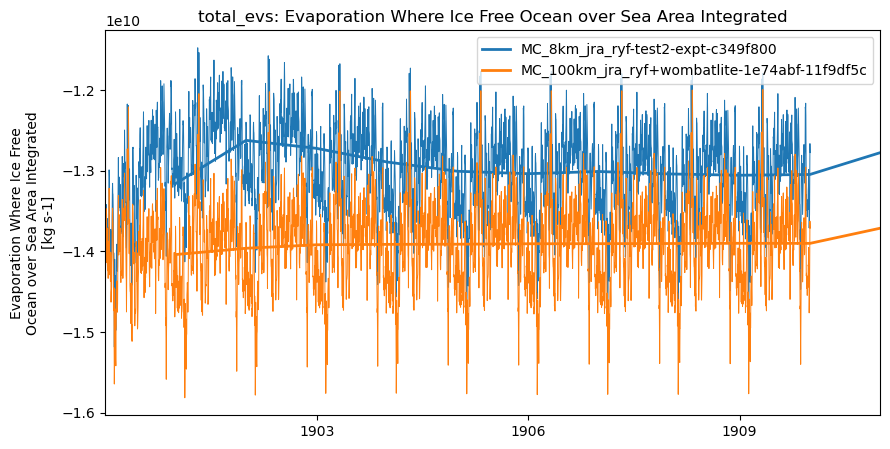

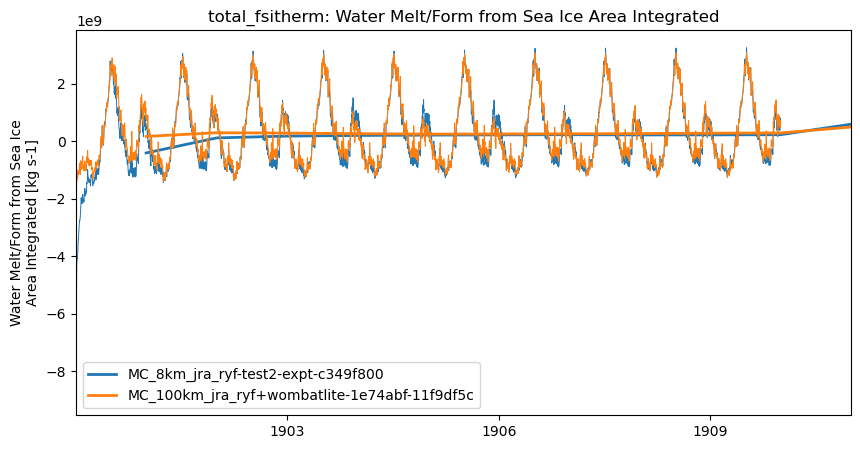

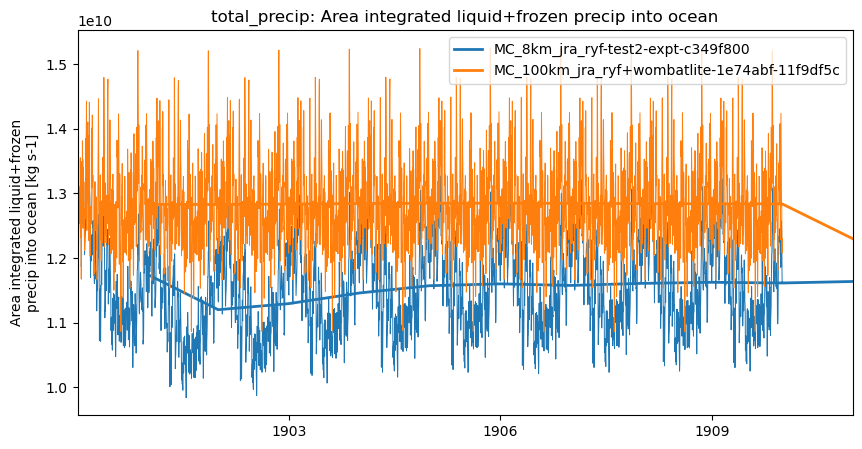

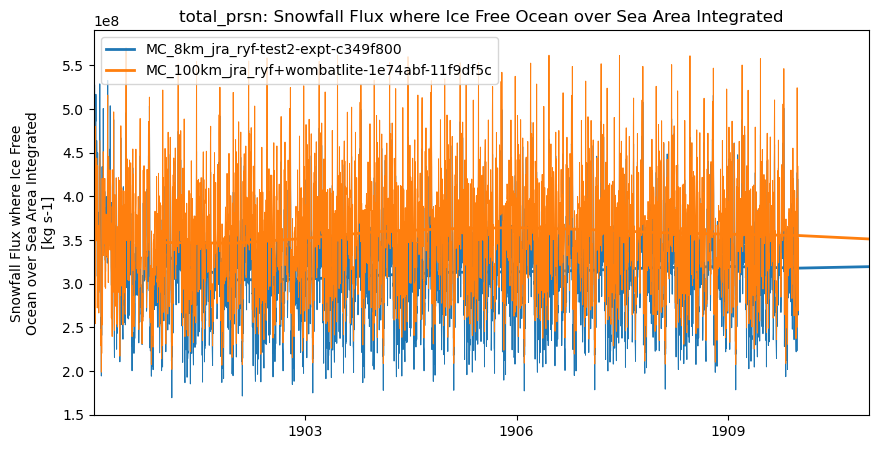

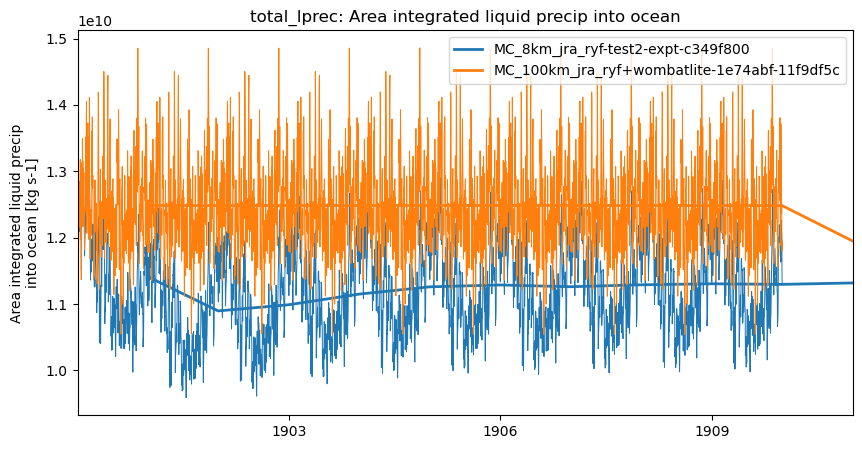

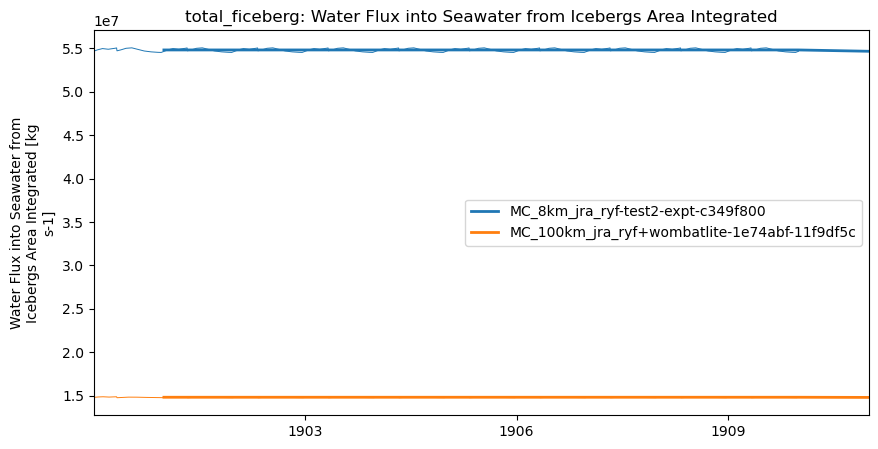

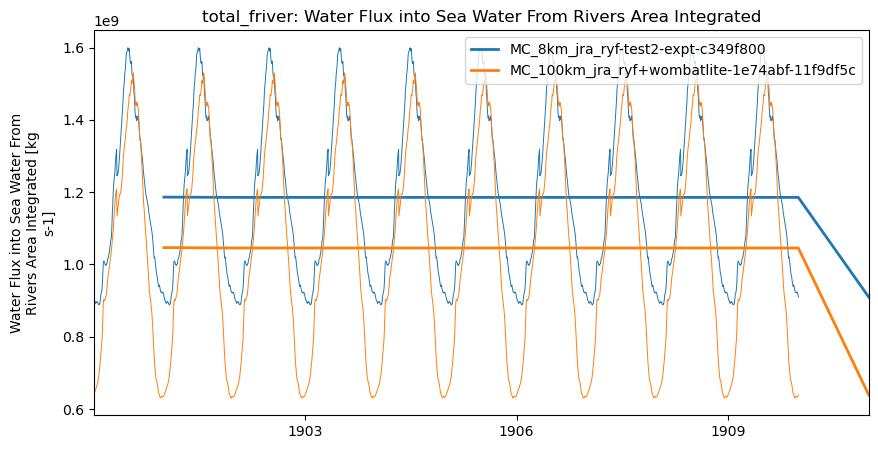

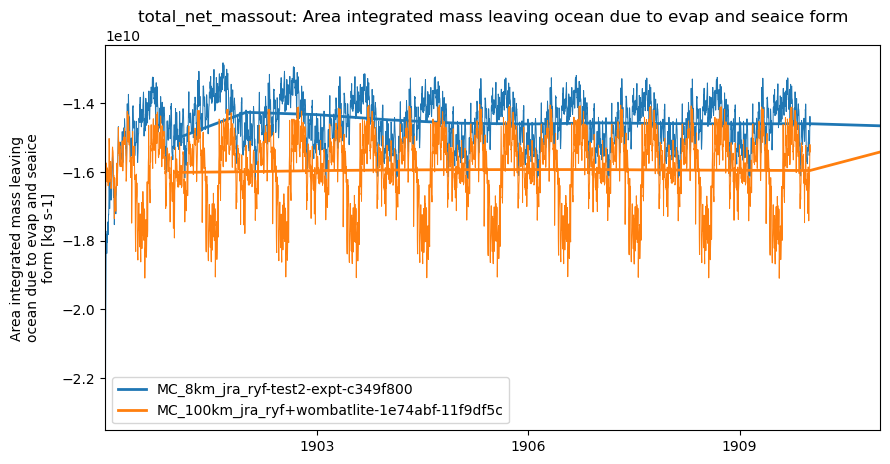

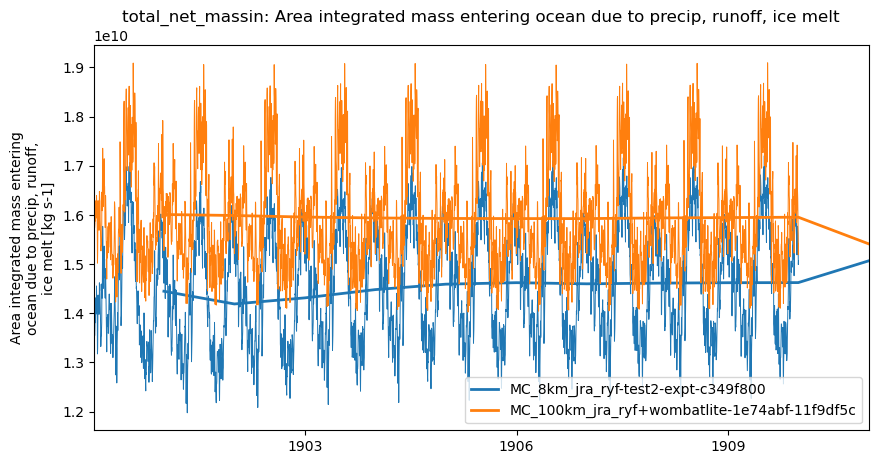

In [20]:
for k, d in data.items():
    print(k)
    fname = thisdir+k+'_'+list(d.values())[-1][k].attrs['long_name'].replace(' ', '_').replace('/','_')+'.png'
    # print(fname)
    if False: #os.path.isfile(fname):
        print(f'---- skipping existing file {fname}')
    else:
        plt.figure(figsize=(10,5))
        ax = plt.subplot(111)
        for n, ds in d.items():
            dat = ds[k].sel(time=trange)
            if dat.cell_methods.find('time: mean') >= 0:
                # calculate spatial average if needed
                if 'depth' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y', 'Z'])
                elif 'longitude' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y'])
            elif dat.cell_methods.find('time: max') >= 0:
                dat = dat.cf.max(dim=['longitude', 'latitude'])
            elif dat.cell_methods.find('time: min') >= 0:
                dat = dat.cf.min(dim=['longitude', 'latitude'])
            # dat = dat - dat.isel(time=0)
            dat.load()
            # if int((dat.time[1]-dat.time[0]).values/1e9/60/60/24) == 1:
            #     label = 'daily'
            # else:
            #     label = 'monthly mean' # possible BUG: plausible guess
            # p = dat.plot(label=' '.join([n, label]), linewidth=1)
            p = dat.plot(linewidth=.7)
            dat.cf.resample(time='1YE').mean('time').plot(
                color=p[-1].get_color(),
                linewidth=2,
                label=n
            )
            # dat.cf.rolling(time=12, center=True).mean('time').plot()
            # dat.cf.rolling(time='1YE', center=True).mean('time').plot()
        # NB: title from first item (OM3), but y axis label from last item (may be OM2)
        # plt.title(k+': '+list(d.values())[0][k].attrs['long_name'])
        plt.title(f'{k}: {dat.attrs["long_name"]}')
        plt.xlabel('')
        plt.autoscale(enable=True, axis='x', tight=True)
        plt.legend()
        # # Shrink current axis's height from the bottom
        # box = ax.get_position()
        # ax.set_position([box.x0, box.y0 + box.height * 0.4,
        #                  box.width, box.height * 0.6])
        # # Put a legend below current axis
        # ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
        # # try:
        #     plt.savefig(fname, dpi=150)
        #     print(f'saved {fname}')
        # except FileNotFoundError:
        #     print(f'*** FileNotFoundError when saving {fname}')
        # break
    mkmd.savefig(plt.gcf(), "Timeseries", "ACCESS-OM3 global model timeseries. [GitHub issue: Global average annual mean time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3)")

soga


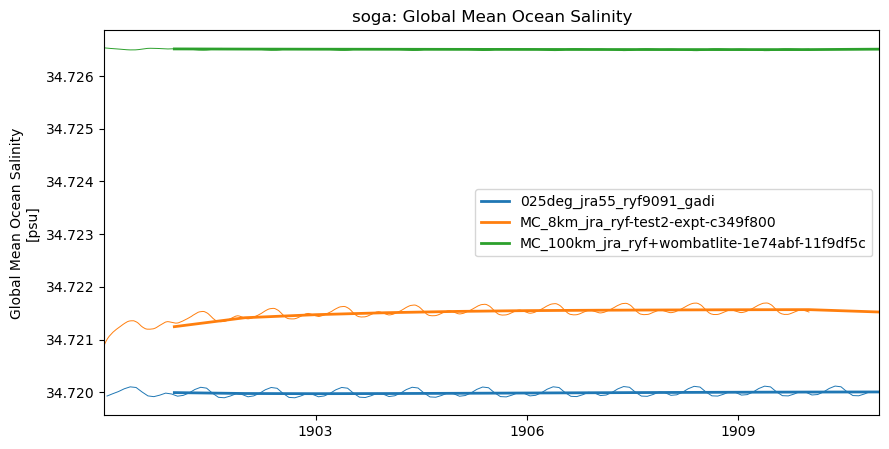

In [21]:
# just plot soga, omitting 25km-iaf-test-for-AK-expt-7df5ef4c
for k, d in data.items():
    if k != "soga":
        continue
    print(k)
    fname = thisdir+k+'_'+list(d.values())[-1][k].attrs['long_name'].replace(' ', '_').replace('/','_')+'.png'
    # print(fname)
    if False: #os.path.isfile(fname):
        print(f'---- skipping existing file {fname}')
    else:
        plt.figure(figsize=(10,5))
        ax = plt.subplot(111)
        for n, ds in d.items():
            if n == "25km-iaf-test-for-AK-expt-7df5ef4c":
                continue
            dat = ds[k].sel(time=trange)
            if dat.cell_methods.find('time: mean') >= 0:
                # calculate spatial average if needed
                if 'depth' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y', 'Z'])
                elif 'longitude' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y'])
            elif dat.cell_methods.find('time: max') >= 0:
                dat = dat.cf.max(dim=['longitude', 'latitude'])
            elif dat.cell_methods.find('time: min') >= 0:
                dat = dat.cf.min(dim=['longitude', 'latitude'])
            # dat = dat - dat.isel(time=0)
            dat.load()
            # if int((dat.time[1]-dat.time[0]).values/1e9/60/60/24) == 1:
            #     label = 'daily'
            # else:
            #     label = 'monthly mean' # possible BUG: plausible guess
            # p = dat.plot(label=' '.join([n, label]), linewidth=1)
            p = dat.plot(linewidth=.7)
            dat.cf.resample(time='1YE').mean('time').plot(
                color=p[-1].get_color(),
                linewidth=2,
                label=n
            )
            # dat.cf.rolling(time=12, center=True).mean('time').plot()
            # dat.cf.rolling(time='1YE', center=True).mean('time').plot()
        # NB: title from first item (OM3), but y axis label from last item (may be OM2)
        # plt.title(k+': '+list(d.values())[0][k].attrs['long_name'])
        plt.title(f'{k}: {dat.attrs["long_name"]}')
        plt.xlabel('')
        plt.autoscale(enable=True, axis='x', tight=True)
        plt.legend()
        # # Shrink current axis's height from the bottom
        # box = ax.get_position()
        # ax.set_position([box.x0, box.y0 + box.height * 0.4,
        #                  box.width, box.height * 0.6])
        # # Put a legend below current axis
        # ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
        # # try:
        #     plt.savefig(fname, dpi=150)
        #     print(f'saved {fname}')
        # except FileNotFoundError:
        #     print(f'*** FileNotFoundError when saving {fname}')
        # break

## Water balance checks

https://github.com/ACCESS-NRI/access-om3-configs/issues/920

In [22]:
esm_name = get_exptname_from_path(esm_file)
esm_name

'MC_8km_jra_ryf-test2-expt-c349f800'

In [23]:
masked_areacello = static['areacello'] + 0*data['tos_max'][esm_name].tos_max.isel(time=0)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 110.89 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


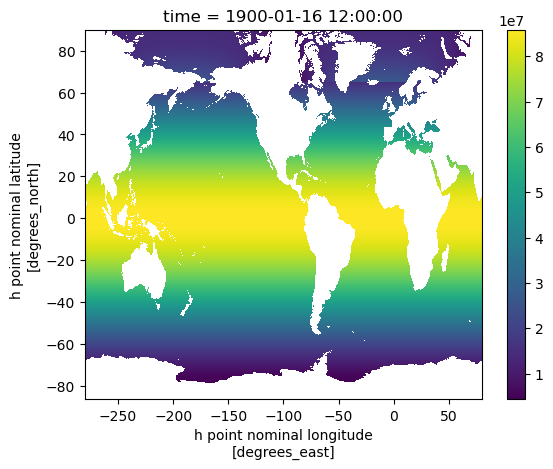

In [24]:
masked_areacello.plot()

In [25]:
total_ocean_area = masked_areacello.sum().load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 110.89 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [26]:
total_fsitherm = data['total_fsitherm'][esm_name]['total_fsitherm'].load()

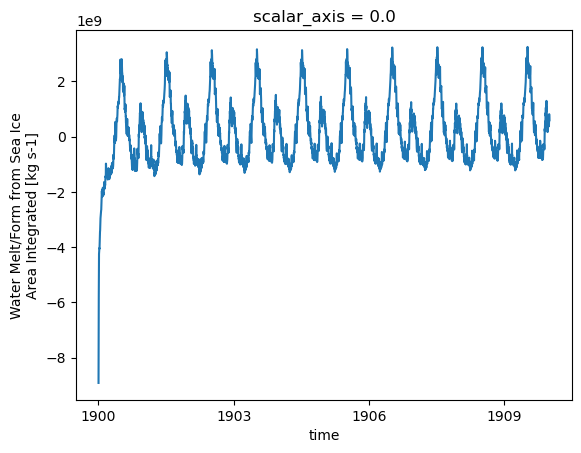

In [27]:
total_fsitherm.plot()

In [28]:
try:
    net_fresh_water_global_adjustment = (data['net_fresh_water_global_adjustment'][esm_name]['net_fresh_water_global_adjustment'] * total_ocean_area).load()
    net_fresh_water_global_adjustment.plot()
    (net_fresh_water_global_adjustment - total_fsitherm).plot()
except KeyError:
    pass